# Análisis de la evaluación con docentes: LLM frente a plantillas

Este cuaderno hace todo el análisis estadístico con **librerías estándar de Python** (pandas, SciPy, statsmodels y krippendorff). Cada medida sigue siempre el mismo orden: **qué calcula → para qué sirve → el código (una línea de la librería) → qué significa el resultado**.

**Cómo usarlo:** Si falta una librería: `pip install pandas scipy statsmodels krippendorff matplotlib`.

**Cómo se lee:** las diferencias siempre son **LLM − plantilla**. Si es positiva, ganó el LLM; si es negativa, ganó la plantilla. En los cinco criterios, 5 es la mejor nota.

**Sobre los docentes:** se recogieron las notas de **cuatro docentes**. Tres enseñan Matemática y **D4 no**. El análisis principal usa a los **cuatro docentes**, como se planificó de antemano. Como análisis adicional de **sensibilidad** se repite todo solo con los tres docentes de Matemática; esa exclusión se pensó **después de ver los resultados**, por eso no reemplaza al análisis principal.

> Este cuaderno lee archivos privados (clave A/B y pistas originales). 

## 0. Preparación
Se cargan los datos y se «destapa» qué pista era del LLM y cuál de la plantilla con la clave A/B. `EXCLUIR` es el docente que no es de Matemática y solo se quita en el análisis de sensibilidad; el análisis principal siempre usa a todos.

In [1]:
import json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.stats.multitest import multipletests
import krippendorff
from IPython.display import display, Markdown

EXCLUIR = ("D4",)          # docente(s) que no son de Matemática (solo se quitan en el análisis de sensibilidad)
GUARDAR_FIGURAS = True     # guarda los gráficos en evaluacion/docentes/figuras/

RAIZ = Path.cwd()
if not (RAIZ / "evaluacion").exists():
    RAIZ = RAIZ.parent  # el cuaderno está en evaluacion/
CARPETA = RAIZ / "evaluacion" / "docentes"
FIGURAS = CARPETA / "figuras"
if GUARDAR_FIGURAS:
    FIGURAS.mkdir(exist_ok=True)
def guardar(nombre):
    if GUARDAR_FIGURAS:
        plt.savefig(FIGURAS / f"{nombre}.png", dpi=200, bbox_inches="tight")

CRIT = ["corr_matematica", "claridad", "adecuacion_nivel", "utilidad", "no_revela"]
NOM = {"corr_matematica": "Corrección matemática", "claridad": "Claridad", "adecuacion_nivel": "Adecuación al nivel",
       "utilidad": "Utilidad (principal)", "no_revela": "No revela la solución"}
SECUNDARIOS = [c for c in CRIT if c != "utilidad"]
AZUL, NARANJA = "#0072B2", "#E69F00"   
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 10})

# Datos
df = pd.read_csv(CARPETA / "calificaciones_docentes.csv", sep=None, engine="python", encoding="utf-8-sig")
df = df.dropna(subset=["docente", "caso"]).astype({"caso": int})   # ignora filas vacías al final del CSV (Excel las agrega)
originales = json.loads((CARPETA / "pistas_originales.json").read_text(encoding="utf-8"))
clave = json.loads((CARPETA / "CLAVE_AB_no_entregar.json").read_text(encoding="utf-8"))
num_a_id = {r["numero_en_hoja"]: cid for cid, r in originales["casos"].items()}
df["id"] = df["caso"].map(num_a_id)  # número de caso -> id del caso
df["mecanismo"] = [clave["asignacion"][i][p.strip().upper()] for i, p in zip(df["id"], df["pista"])]   # A/B -> llm/plantilla
df["categoria"] = df["id"].map(lambda i: originales["casos"][i]["categoria"])

# Grupos de docentes que se comparan
df_mat = df[~df["docente"].isin(EXCLUIR)]
grupos = {"Todos los docentes (análisis principal)": df, "Docentes de Matemática (análisis de sensibilidad)": df_mat} if EXCLUIR else {"Todos los docentes (análisis principal)": df}

def diferencias(d, criterio):
    """Diferencia LLM − plantilla por caso (promedio entre los docentes que calificaron las dos pistas)."""
    t = d.pivot_table(index=["id", "docente"], columns="mecanismo", values=criterio).dropna()
    return (t["llm"] - t["plantilla"]).groupby("id").mean()

DIF = {g: {c: diferencias(d, c) for c in CRIT} for g, d in grupos.items()}      # 30 diferencias por criterio y grupo

## 1. Revisión rápida de los datos
Se comprueba que no falte nada: cada docente debe tener 60 filas (30 casos × 2 pistas) y todas las notas deben estar entre 1 y 5.

In [2]:
assert df[CRIT].stack().between(1, 5).all(), "Hay notas fuera de 1 a 5"
assert not df.duplicated(["docente", "caso", "pista"]).any(), "Hay filas repetidas"
display(df.groupby("docente").agg(filas=("caso", "size"), casos=("id", "nunique"), celdas_vacias=("claridad", lambda s: 0)).assign(
        celdas_vacias=df.groupby("docente")[CRIT].apply(lambda g: int(g.isna().sum().sum()))))

,filas,casos,celdas_vacias
docente,,,
D1,60,30,0
D2,60,30,0
D3,60,30,0
D4,60,30,0


## 2. Medida 1 — Promedio y desviación típica: qué tan altas fueron las notas
**Qué calcula:** la nota promedio (`mean`), cuánto se alejan las notas de ese promedio (`std`, desviación típica) y la nota del medio (`median`) de cada tipo de pista.

**Para qué sirve:** ver cómo calificaron los docentes, sin comparar todavía.

In [3]:
for g, d in grupos.items():
    print(g)
    display(d.groupby("mecanismo")[CRIT].agg(["mean", "std", "median"]).round(2).T)    

Todos los docentes (análisis principal)


mecanismo                 llm  plantilla
corr_matematica  mean    4.58       4.53
                 std     0.87       0.88
                 median  5.00       5.00
claridad         mean    4.41       4.58
                 std     0.75       0.68
                 median  5.00       5.00
adecuacion_nivel mean    4.44       4.38
                 std     0.66       0.74
                 median  5.00       5.00
utilidad         mean    4.40       4.58
                 std     0.81       0.76
                 median  5.00       5.00
no_revela        mean    4.45       3.38
                 std     0.82       1.38
                 median  5.00       3.00

Docentes de Matemática (análisis de sensibilidad)


mecanismo                 llm  plantilla
corr_matematica  mean    4.61       4.40
                 std     0.91       0.97
                 median  5.00       5.00
claridad         mean    4.59       4.52
                 std     0.65       0.72
                 median  5.00       5.00
adecuacion_nivel mean    4.62       4.37
                 std     0.53       0.74
                 median  5.00       5.00
utilidad         mean    4.62       4.51
                 std     0.63       0.80
                 median  5.00       5.00
no_revela        mean    4.47       3.27
                 std     0.82       1.38
                 median  5.00       3.00

**Qué significa:** si casi todas las medias están cerca de 4 y 5 y la mediana es 5, hay **efecto techo**: las notas se pegan al máximo y la rúbrica distingue poco entre pistas buenas y muy buenas. Una media baja con desviación grande (por ejemplo, «No revela» en la plantilla) indica un problema real de ese tipo de pista.

El gráfico muestra **todas** las notas (no solo el promedio): cuántas fueron 1, 2, 3, 4 y 5.

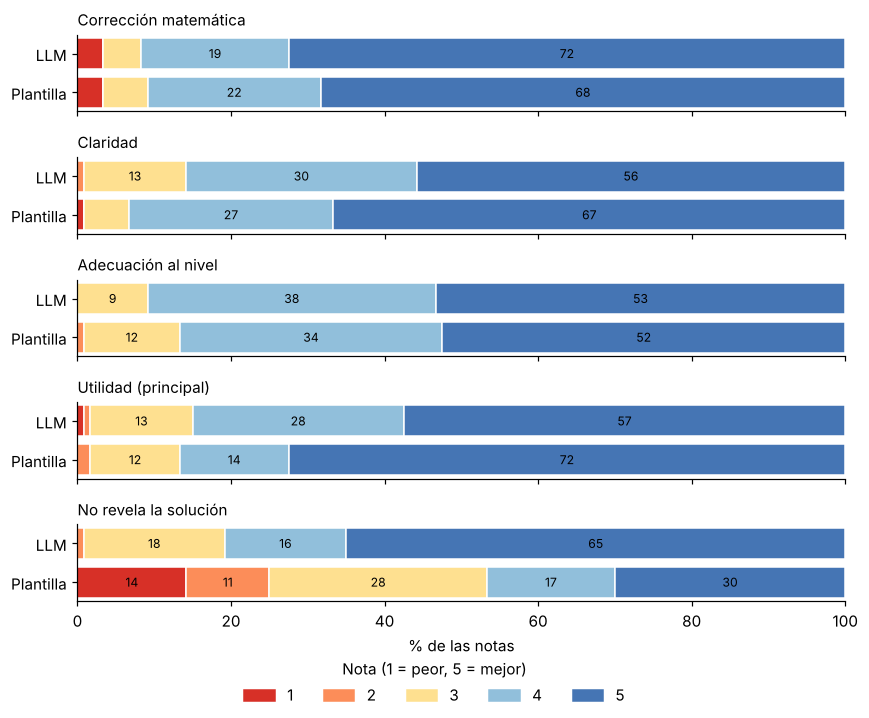

In [4]:
fig, axes = plt.subplots(len(CRIT), 1, figsize=(8, 1.15 * len(CRIT) + 0.8), sharex=True)
tonos = ["#d73027", "#fc8d59", "#fee090", "#91bfdb", "#4575b4"] # de la nota 1 (peor) a la 5 (mejor)
for ax, c in zip(axes, CRIT):
    for k, m in enumerate(["plantilla", "llm"]):
        pct = df.loc[df["mecanismo"] == m, c].value_counts(normalize=True).reindex(range(1, 6), fill_value=0) * 100
        izq = 0
        for nota in range(1, 6):
            ax.barh(k, pct[nota], left=izq, color=tonos[nota - 1], edgecolor="white")
            if pct[nota] >= 8: ax.text(izq + pct[nota] / 2, k, f"{pct[nota]:.0f}", ha="center", va="center", fontsize=8)
            izq += pct[nota]
    ax.set_yticks([0, 1]); ax.set_yticklabels(["Plantilla", "LLM"]); ax.set_title(NOM[c], loc="left", fontsize=10); ax.set_xlim(0, 100)
axes[-1].set_xlabel("% de las notas")
fig.tight_layout(rect=(0, 0.06, 1, 1))
fig.legend([plt.Rectangle((0, 0), 1, 1, color=t) for t in tonos], ["1", "2", "3", "4", "5"], title="Nota (1 = peor, 5 = mejor)", ncol=5, loc="lower center", frameon=False)
guardar("01_distribucion_notas"); plt.show()

## 3. Medida 2 — Diferencia por caso e intervalo de confianza: cuánto mejor es una pista que otra
**Qué calcula:** para cada caso, la nota de la pista del LLM **menos** la de la plantilla (promediada entre docentes). Salen 30 diferencias por criterio. Comparar **dentro del mismo caso** evita que unos casos sean más difíciles que otros. Con la diferencia media se calcula el **intervalo de confianza (IC) del 95 %** con *bootstrap*: se repite 10 000 veces el cálculo con casos sacados al azar y se toma el rango donde cae el 95 % central.

**Para qué sirve:** saber **cuánto** mejor es una pista que otra y con **cuánta incertidumbre**.

In [5]:
IC = {}
for g in grupos:
    IC[g] = {}
    for c in CRIT:
        r = stats.bootstrap((DIF[g][c].values,), np.mean, n_resamples=10000, confidence_level=0.95,
                            method="percentile", random_state=np.random.default_rng(20261110)) 
        IC[g][c] = (r.confidence_interval.low, r.confidence_interval.high)
    print(g)
    display(pd.DataFrame({"Diferencia media": {NOM[c]: DIF[g][c].mean() for c in CRIT},
                          "IC 95 % desde": {NOM[c]: IC[g][c][0] for c in CRIT},
                          "IC 95 % hasta": {NOM[c]: IC[g][c][1] for c in CRIT}}).round(2))

Todos los docentes (análisis principal)


,Diferencia media,IC 95 % desde,IC 95 % hasta
Corrección matemática,0.05,-0.05,0.14
Claridad,-0.18,-0.40,0.05
Adecuación al nivel,0.06,-0.07,0.18
Utilidad (principal),-0.18,-0.32,-0.03
No revela la solución,1.08,0.72,1.42


Docentes de Matemática (análisis de sensibilidad)


,Diferencia media,IC 95 % desde,IC 95 % hasta
Corrección matemática,0.21,0.10,0.32
Claridad,0.07,-0.20,0.34
Adecuación al nivel,0.26,0.12,0.39
Utilidad (principal),0.11,-0.08,0.31
No revela la solución,1.20,0.84,1.56


**Qué significa:** el IC describe **qué tan precisa es la estimación** de la diferencia. Si el rango **no incluye el 0**, hay evidencia de una diferencia (positiva = a favor del LLM; negativa = a favor de la plantilla), pero no una prueba segura: depende del método y de los supuestos. Si **incluye el 0**, los datos son compatibles con que no haya diferencia. Aquí el IC solo **describe**; la decisión de significancia se toma con las pruebas de la sección 5. En el gráfico, el punto es la diferencia media, la línea es el IC y la banda gris es la zona de diferencias pequeñas (menos de 0,3 puntos).

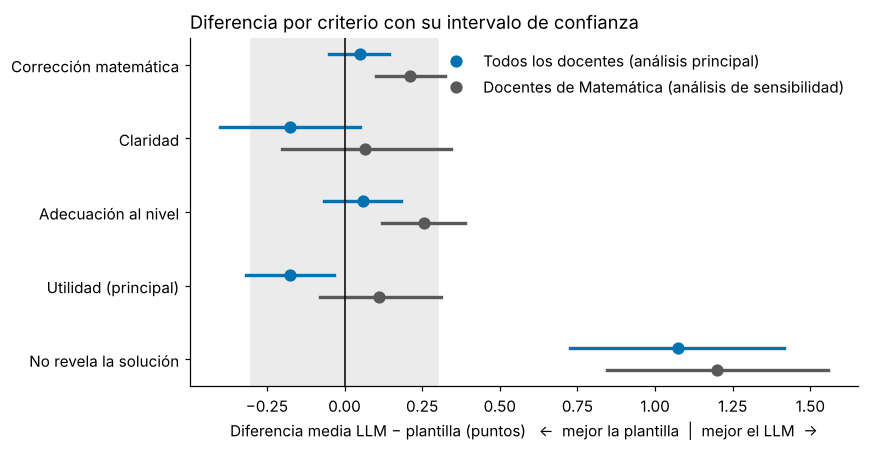

In [6]:
fig, ax = plt.subplots(figsize=(8, 4.2))
colores = [AZUL, "0.35"]
for k, g in enumerate(grupos):
    desp = (k - (len(grupos) - 1) / 2) * 0.3
    for i, c in enumerate(CRIT):
        ax.plot(IC[g][c], [i + desp] * 2, color=colores[k], lw=2.2)
        ax.plot(DIF[g][c].mean(), i + desp, "o", color=colores[k], ms=7, label=g if i == 0 else None)
ax.axvline(0, color="black", lw=1); ax.axvspan(-0.3, 0.3, color="0.92", zorder=0)
ax.set_yticks(range(len(CRIT))); ax.set_yticklabels([NOM[c] for c in CRIT]); ax.invert_yaxis()
ax.set_xlabel("Diferencia media LLM − plantilla (puntos)   ←  mejor la plantilla  |  mejor el LLM  →")
ax.legend(frameon=False, loc="upper right"); ax.set_title("Diferencia por criterio con su intervalo de confianza", loc="left")
fig.tight_layout(); guardar("02_diferencias_con_IC"); plt.show()

## 4. Medida 3 — Casos a favor de cada pista: quién gana en más casos
**Qué calcula:** de los 30 casos, en cuántos la pista del LLM tuvo mejor nota (diferencia mayor que 0), en cuántos la plantilla (menor que 0) y en cuántos hubo empate (igual a 0).

**Para qué sirve:** tener una idea sencilla, sin fórmulas.

In [7]:
for g in grupos:
    print(g)
    display(pd.DataFrame({NOM[c]: {"Gana el LLM": (DIF[g][c] > 0).sum(), "Gana la plantilla": (DIF[g][c] < 0).sum(), "Empate": (DIF[g][c] == 0).sum()}
                          for c in CRIT}).T)

Todos los docentes (análisis principal)


,Gana el LLM,Gana la plantilla,Empate
Corrección matemática,11,5,14
Claridad,8,15,7
Adecuación al nivel,10,7,13
Utilidad (principal),5,15,10
No revela la solución,25,3,2


Docentes de Matemática (análisis de sensibilidad)


,Gana el LLM,Gana la plantilla,Empate
Corrección matemática,18,2,10
Claridad,14,10,6
Adecuación al nivel,17,4,9
Utilidad (principal),10,8,12
No revela la solución,25,3,2


**Qué significa:** si el reparto es parecido (por ejemplo 10 / 8 / 12), ninguna pista gana claramente. Si es muy desigual (por ejemplo 25 / 3 / 2), hay una tendencia clara.

## 5. Medida 4 — Prueba de Wilcoxon y corrección de Holm: si la diferencia puede ser azar
**Qué calcula (Wilcoxon):**
1. Toma las 30 diferencias y descarta las que valen 0.
2. Las ordena por tamaño (sin mirar el signo) y les da un número de orden (rango).
3. Suma los rangos de las positivas (gana el LLM) y de las negativas (gana la plantilla).
4. Si una suma es mucho mayor que la otra, es poco probable que sea azar. Eso lo resume el **valor p**.

**Para qué sirve:** decidir si una diferencia es «significativa». Se usa Wilcoxon (y no la prueba t) porque las notas son del 1 al 5 y son pocos casos, así que no podemos suponer que las diferencias tengan forma de campana.

**Prueba de signos exacta (comprobación):** Wilcoxon se interpreta como un cambio «típico» de las diferencias cuando estas son más o menos simétricas, y aquí se aplica a diferencias promediadas entre docentes (no a las notas originales). Por eso se añade una prueba que no supone simetría: la de signos cuenta cuántos casos gana cada pista (sin contar empates) y pregunta si ese reparto se aleja de 50 % / 50 %, como lo haría una moneda.

**Holm:** los cuatro criterios secundarios se prueban a la vez; si pruebas muchas veces, alguna sale significativa por pura suerte. Holm hace el p más exigente para evitarlo. La utilidad (el criterio principal) se prueba sola, sin corrección.

In [8]:
P, PH, PS = {}, {}, {}
for g in grupos:
    P[g] = {c: stats.wilcoxon(DIF[g][c], method="approx", correction=False).pvalue for c in CRIT} # SciPy (descarta los 0)
    PH[g] = dict(zip(SECUNDARIOS, multipletests([P[g][c] for c in SECUNDARIOS], method="holm")[1])) # statsmodels
    PS[g] = {c: stats.binomtest(int((DIF[g][c] > 0).sum()), int((DIF[g][c] != 0).sum()), 0.5).pvalue for c in CRIT} # SciPy: prueba de signos exacta
    print(g)
    display(pd.DataFrame({"p (Wilcoxon)": {NOM[c]: P[g][c] for c in CRIT},
                          "p corregido (Holm)": {NOM[c]: PH[g].get(c, np.nan) for c in CRIT},
                          "p (prueba de signos)": {NOM[c]: PS[g][c] for c in CRIT}}).map(lambda x: "—" if pd.isna(x) else ("< 0,001" if x < 0.001 else f"{x:.3f}")))

Todos los docentes (análisis principal)


,p (Wilcoxon),p corregido (Holm),p (prueba de signos)
Corrección matemática,0.404,0.757,0.210
Claridad,0.125,0.376,0.210
Adecuación al nivel,0.379,0.757,0.629
Utilidad (principal),0.034,—,0.041
No revela la solución,"< 0,001","< 0,001","< 0,001"


Docentes de Matemática (análisis de sensibilidad)


,p (Wilcoxon),p corregido (Holm),p (prueba de signos)
Corrección matemática,0.002,0.005,"< 0,001"
Claridad,0.806,0.806,0.541
Adecuación al nivel,0.002,0.005,0.007
Utilidad (principal),0.279,—,0.815
No revela la solución,"< 0,001","< 0,001","< 0,001"


**Qué significa:** el valor p es la probabilidad de ver una diferencia así si en realidad no hubiera ninguna. **Menor que 0,05: es poco probable que sea azar (significativo).** Mayor que 0,05: **podría ser azar** (no significativo). Para los cuatro criterios secundarios se mira el p corregido. La prueba de signos es una **comprobación**: si coincide con Wilcoxon (ambas menores o ambas mayores que 0,05), la conclusión es más sólida; si no, hay que decirlo. El p **no** dice qué tan grande es la diferencia, solo si parece azar.

## 6. Medida 5 — Tamaño de la diferencia: si la diferencia importa
**Qué calcula:** qué tan grande es la diferencia media, en puntos de la escala de 1 a 5. Pequeña: menos de 0,3; moderada: de 0,3 a menos de 0,7; grande: 0,7 o más (convención de este trabajo).

**Para qué sirve:** distinguir una diferencia que **importa** de una que solo es **estadística**.

In [9]:
def magnitud(x):
    return "pequeña" if abs(x) < 0.3 else ("moderada" if abs(x) < 0.7 else "grande")

MAG = {g: {c: magnitud(DIF[g][c].mean()) for c in CRIT} for g in grupos}
for g in grupos:
    print(g)
    display(pd.DataFrame({"Diferencia media": {NOM[c]: DIF[g][c].mean() for c in CRIT}, "Tamaño": {NOM[c]: MAG[g][c] for c in CRIT}}).round(2))

Todos los docentes (análisis principal)


,Diferencia media,Tamaño
Corrección matemática,0.05,pequeña
Claridad,-0.18,pequeña
Adecuación al nivel,0.06,pequeña
Utilidad (principal),-0.18,pequeña
No revela la solución,1.08,grande


Docentes de Matemática (análisis de sensibilidad)


,Diferencia media,Tamaño
Corrección matemática,0.21,pequeña
Claridad,0.07,pequeña
Adecuación al nivel,0.26,pequeña
Utilidad (principal),0.11,pequeña
No revela la solución,1.20,grande


**Qué significa:** una diferencia puede ser significativa y aun así muy pequeña (por ejemplo, 0,2 puntos entre notas que ya son altas). **No es lo mismo «significativo» que «importante».**

## 7. Medida 6 — Acuerdo entre docentes: si los docentes coinciden
**Qué calcula:** qué tanto coinciden los docentes al calificar la misma pista, **descontando lo que coincidirían por azar** (alfa de Krippendorff, versión ordinal). También el % de pistas en que los docentes se diferencian en 1 punto o menos.

**Para qué sirve:** saber si las diferencias vienen de las pistas o de los gustos de cada docente.

In [10]:
ALFA = {}
for g, d in grupos.items():
    ALFA[g] = {}
    for c in CRIT:
        m = d.pivot_table(index="docente", columns=["id", "pista"], values=c)                 # docentes × pistas calificadas
        ALFA[g][c] = krippendorff.alpha(reliability_data=m.values, level_of_measurement="ordinal")      # librería krippendorff
    print(g)
    display(pd.DataFrame({"Alfa de Krippendorff": {NOM[c]: ALFA[g][c] for c in CRIT},
                          "% de pistas con diferencia ≤ 1 punto": {NOM[c]: ((d.groupby(["id", "pista"])[c].max() - d.groupby(["id", "pista"])[c].min()) <= 1).mean() * 100 for c in CRIT}}).round(2))

Todos los docentes (análisis principal)


,Alfa de Krippendorff,% de pistas con diferencia ≤ 1 punto
Corrección matemática,0.11,73.33
Claridad,0.14,78.33
Adecuación al nivel,-0.18,61.67
Utilidad (principal),0.01,53.33
No revela la solución,0.36,35.00


Docentes de Matemática (análisis de sensibilidad)


,Alfa de Krippendorff,% de pistas con diferencia ≤ 1 punto
Corrección matemática,0.25,78.33
Claridad,0.25,93.33
Adecuación al nivel,-0.27,80.00
Utilidad (principal),0.06,71.67
No revela la solución,0.37,36.67


**Qué significa:** el alfa va de −1 a 1: **1 es acuerdo total**, **0 es como calificar al azar** y negativo es peor que el azar. Desde 0,67 se considera aceptable. Casi todos los valores de esta tabla están muy por debajo, y en la utilidad (criterio principal) el acuerdo corregido por azar es casi nulo. Eso limita lo que se puede concluir: una misma pista pudo recibir 5 puntos de un docente y 3 de otro, y por eso las diferencias pequeñas no deben presentarse como ventajas consolidadas. Se discute más en el documento.

**Cuidado con la causa:** el efecto techo (casi todo es 4 o 5) baja el alfa aunque los docentes estén cerca, pero no es la única explicación posible: también pueden pesar criterios distintos de cada docente (qué es «útil»), pistas realmente ambiguas o una rúbrica interpretada de varias formas. En la adecuación al nivel el alfa es **negativo**: los docentes discrepan más de lo que habría por azar. Las siguientes celdas muestran dónde discreparon.

### 7.1 Pistas donde los docentes discreparon mucho
Se listan las pistas cuya nota más alta y más baja difieren en **2 puntos o más** (utilidad y adecuación al nivel), con la nota de cada docente y el texto de la pista.

In [11]:
dg = list(grupos.values())[0]
for c in ["utilidad", "adecuacion_nivel"]:
    t = dg.pivot_table(index=["id", "mecanismo"], columns="docente", values=c)
    t = t[(t.max(axis=1) - t.min(axis=1)) >= 2]
    print(f"{NOM[c]}: {len(t)} pistas con discrepancia de 2 puntos o más (de {dg.groupby(['id','mecanismo']).ngroups})")
    for (cid, mec), fila in t.sort_values(by=list(t.columns)[0]).head(8).iterrows():
        notas = ", ".join(f"{dc} = {v:.0f}" for dc, v in fila.items())
        print(f"  Caso {originales['casos'][cid]['numero_en_hoja']} ({mec}): {notas}")
        print(f"     «{originales['casos'][cid][mec]['texto']}»")
    print()

Utilidad (principal): 28 pistas con discrepancia de 2 puntos o más (de 60)
  Caso 3 (plantilla): D1 = 3, D2 = 4, D3 = 5, D4 = 5
     «Revisa el signo del término 1.5: al moverlo al otro lado de la ecuación, su signo debe cambiar.»
  Caso 25 (llm): D1 = 3, D2 = 3, D3 = 5, D4 = 4
     «Revisa con calma el cálculo del lado derecho de la ecuación. La forma de combinar esos números es la adecuada, así que concéntrate en las operaciones numéricas. ¿Qué resultado obtienes al repetirlas?»
  Caso 5 (plantilla): D1 = 4, D2 = 3, D3 = 5, D4 = 5
     «Revisa el cálculo numérico del lado derecho: la operación que aplicaste es correcta, pero el resultado no lo es.»
  Caso 1 (llm): D1 = 4, D2 = 4, D3 = 5, D4 = 3
     «Revisa el paso donde quitaste el paréntesis del segundo término. Fíjate en el signo que va antes del paréntesis y en cómo quedan los signos de los términos que estaban dentro. ¿Todos conservan el mismo signo que tenían?»
  Caso 4 (plantilla): D1 = 4, D2 = 2, D3 = 3, D4 = 5
     «Revisa e

**Qué significa:** si las discrepancias se concentran en un tipo de pista (por ejemplo, las que preguntan en vez de indicar), el desacuerdo refleja una diferencia de criterio pedagógico y no solo ruido. Eso es una hipótesis para la discusión, no una conclusión.

## 8. Medida 7 — Resultado final: ¿es significativo?
**Qué calcula:** reúne las medidas anteriores. Un criterio es **significativo** cuando su p (o p corregido, en los secundarios) es **menor que 0,05** y además su IC 95 % **no incluye el 0**.

**Para qué sirve:** responder la pregunta de la tesis: ¿las pistas del LLM son mejores que las de plantilla?

In [12]:
def significativo(g, c):
    p = P[g][c] if c == "utilidad" else PH[g][c]
    lo, hi = IC[g][c]
    return p < 0.05 and (lo > 0 or hi < 0)

for g in grupos:
    print(g)
    filas = []
    for c in CRIT:
        dif, sig = DIF[g][c].mean(), significativo(g, c)
        filas.append({"Criterio": NOM[c], "Diferencia": round(dif, 2), "¿Significativo?": "SÍ" if sig else "NO",
                      "A favor de": ("el LLM" if dif > 0 else "la plantilla") if sig else "—", "Tamaño": MAG[g][c] if sig else "—",
                      "¿Lo confirma la prueba de signos?": "SÍ" if (PS[g][c] < 0.05) == sig else "NO"})
    display(pd.DataFrame(filas).set_index("Criterio"))
    print("Criterio principal (utilidad):", "SÍ es significativo." if significativo(g, "utilidad") else "NO es significativo: no hay evidencia de que una pista sea más útil que la otra.", "\n")

Todos los docentes (análisis principal)


,Diferencia,¿Significativo?,A favor de,Tamaño,¿Lo confirma la prueba de signos?
Criterio,,,,,
Corrección matemática,0.05,NO,—,—,SÍ
Claridad,-0.18,NO,—,—,SÍ
Adecuación al nivel,0.06,NO,—,—,SÍ
Utilidad (principal),-0.18,SÍ,la plantilla,pequeña,SÍ
No revela la solución,1.08,SÍ,el LLM,grande,SÍ


Criterio principal (utilidad): SÍ es significativo. 

Docentes de Matemática (análisis de sensibilidad)


,Diferencia,¿Significativo?,A favor de,Tamaño,¿Lo confirma la prueba de signos?
Criterio,,,,,
Corrección matemática,0.21,SÍ,el LLM,pequeña,SÍ
Claridad,0.07,NO,—,—,SÍ
Adecuación al nivel,0.26,SÍ,el LLM,pequeña,SÍ
Utilidad (principal),0.11,NO,—,—,SÍ
No revela la solución,1.20,SÍ,el LLM,grande,SÍ


Criterio principal (utilidad): NO es significativo: no hay evidencia de que una pista sea más útil que la otra. 



## 9. Gráficos y tablas adicionales
### 9.1 ¿Todos los docentes opinan lo mismo?
Cada celda es la diferencia media LLM − plantilla de un docente en un criterio. Azul = prefirió el LLM; naranja = prefirió la plantilla. Si una fila entera tiene otro color que las demás, ese docente califica distinto del resto (con los cuatro docentes).

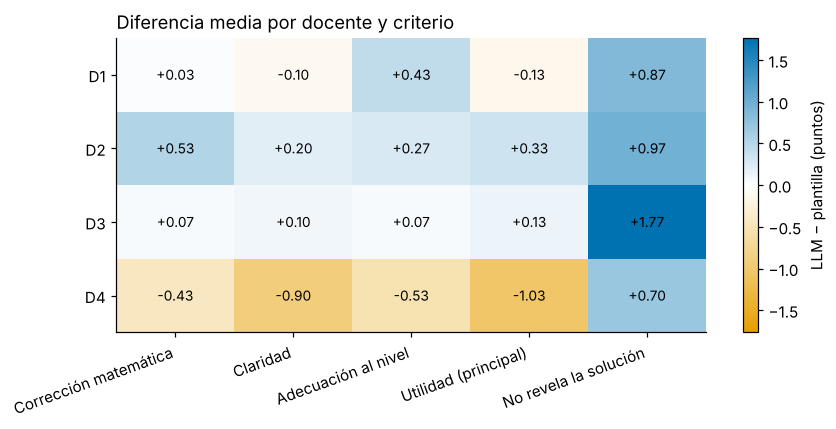

In [13]:
por_docente = pd.DataFrame({dc: {NOM[c]: diferencias(df[df["docente"] == dc], c).mean() for c in CRIT} for dc in sorted(df["docente"].unique())}).T
from matplotlib.colors import LinearSegmentedColormap
mapa = LinearSegmentedColormap.from_list("m", [NARANJA, "#ffffff", AZUL])
lim = max(1.0, np.abs(por_docente.values).max())
fig, ax = plt.subplots(figsize=(8, 0.6 * len(por_docente) + 1.6))
im = ax.imshow(por_docente.values, cmap=mapa, vmin=-lim, vmax=lim, aspect="auto")
ax.set_xticks(range(len(por_docente.columns))); ax.set_xticklabels(por_docente.columns, rotation=20, ha="right")
ax.set_yticks(range(len(por_docente.index))); ax.set_yticklabels(por_docente.index)
for i in range(por_docente.shape[0]):
    for j in range(por_docente.shape[1]):
        ax.text(j, i, f"{por_docente.values[i, j]:+.2f}", ha="center", va="center", fontsize=9)
fig.colorbar(im, ax=ax, label="LLM − plantilla (puntos)"); ax.set_title("Diferencia media por docente y criterio", loc="left")
fig.tight_layout(); guardar("03_diferencia_por_docente"); plt.show()

### 9.2 Utilidad caso por caso
Cada barra es un caso (promedio de los docentes del análisis principal). Sirve para ver si el resultado viene de pocos casos extremos o de una tendencia general.

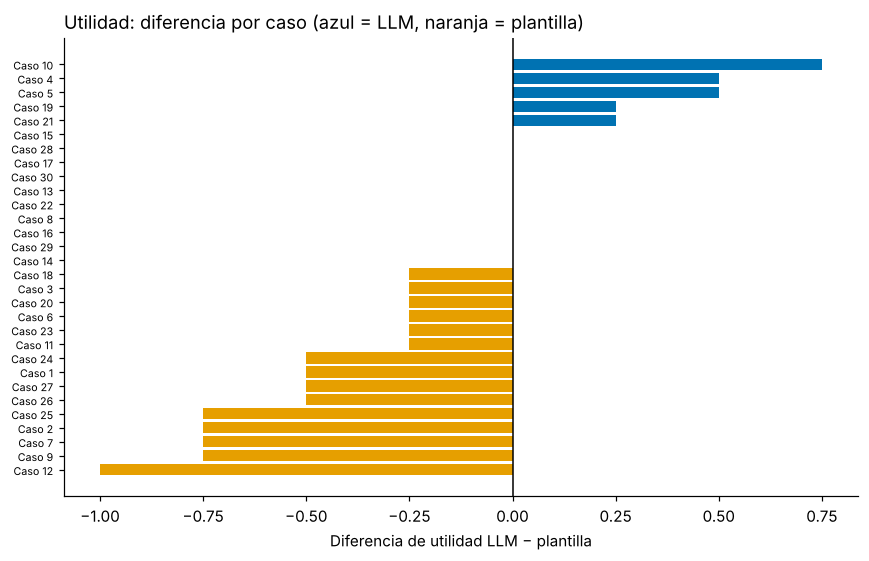

Desviación típica de las diferencias entre casos: 0.41


In [14]:
g0 = list(grupos)[0]
u = DIF[g0]["utilidad"].sort_values()
fig, ax = plt.subplots(figsize=(8, 5.2))
ax.barh([f"Caso {num_a_id_inv}" for num_a_id_inv in [originales["casos"][i]["numero_en_hoja"] for i in u.index]], u.values,
        color=[AZUL if v > 0 else (NARANJA if v < 0 else "0.6") for v in u.values])
ax.axvline(0, color="black", lw=1); ax.tick_params(axis="y", labelsize=7)
ax.set_xlabel("Diferencia de utilidad LLM − plantilla"); ax.set_title("Utilidad: diferencia por caso (azul = LLM, naranja = plantilla)", loc="left")
fig.tight_layout(); guardar("04_utilidad_por_caso"); plt.show()
print("Desviación típica de las diferencias entre casos:", round(u.std(), 2))

### 9.3 Utilidad por categoría de error
Cada categoría tiene solo 6 casos: esto **describe, no concluye**.

In [15]:
cat = df["id"].map(lambda i: originales["casos"][i]["categoria"])
for g, d in grupos.items():
    print(g)
    display(DIF[g]["utilidad"].groupby(DIF[g]["utilidad"].index.map(lambda i: originales["casos"][i]["categoria"])).mean().round(2).sort_values().to_frame("Diferencia media de utilidad"))

Todos los docentes (análisis principal)


,Diferencia media de utilidad
id,
distributiva_incorrecta,-0.42
division_coeficiente_equivocado,-0.29
error_signo,-0.21
operacion_un_lado,-0.08
simplificacion_aritmetica,0.12


Docentes de Matemática (análisis de sensibilidad)


,Diferencia media de utilidad
id,
distributiva_incorrecta,-0.11
division_coeficiente_equivocado,-0.11
operacion_un_lado,0.00
error_signo,0.17
simplificacion_aritmetica,0.61


### 9.4 Sensibilidad: ¿cambia algo sin el caso marcado por la revisión automática?
La revisión automática marcó pistas con formato fuera de lo pedido o que parecían revelar la solución. Se repite la comparación sin esos casos.

In [16]:
marcados = [cid for cid, r in originales["casos"].items() if any(r[m]["incumplimientos"] or r[m]["revela_solucion"] for m in ("llm", "plantilla"))]
print("Casos excluidos:", ", ".join(marcados) or "ninguno")
g0 = list(grupos)[0]
display(pd.DataFrame({NOM[c]: {"Diferencia (todos los casos)": DIF[g0][c].mean(), "Diferencia (sin marcados)": DIF[g0][c].drop(marcados, errors="ignore").mean(),
                               "p (todos)": P[g0][c], "p (sin marcados)": stats.wilcoxon(DIF[g0][c].drop(marcados, errors="ignore"), method="approx", correction=False).pvalue}
                      for c in CRIT}).T.round(3))

Casos excluidos: PC-077


,Diferencia (todos los casos),Diferencia (sin marcados),p (todos),p (sin marcados)
Corrección matemática,0.050,0.043,0.404,0.498
Claridad,-0.175,-0.172,0.125,0.141
Adecuación al nivel,0.058,0.060,0.379,0.379
Utilidad (principal),-0.175,-0.164,0.034,0.050
No revela la solución,1.075,1.060,0.000,0.000


## 10. Análisis cualitativo: pistas reales de casos elegidos con reglas fijas
Los casos no se eligen a mano, sino con reglas del plan, aplicadas a los **cuatro docentes**: los 3 casos donde el LLM ganó por más en utilidad, los 3 donde ganó la plantilla por más, los empates con mayor utilidad, y las pistas con nota media de 2,5 o menos en algún criterio. Sirve para explicar **por qué** una pista funcionó mejor.

In [17]:
todos = list(grupos)[0]   # análisis principal (los cuatro docentes), como en el plan
util = DIF[todos]["utilidad"]
media_util = df.groupby("id")["utilidad"].mean()
def rasgos(t):
    return f"{len(t.split())} palabras, {'con' if '¿' in t else 'sin'} pregunta, {'menciona' if any(ch.isdigit() for ch in t) else 'no menciona'} números"
def mostrar(cid):
    r = originales["casos"][cid]; u = df[df["id"] == cid].groupby("mecanismo")["utilidad"].mean()
    print(f"Caso {r['numero_en_hoja']} ({cid}, {r['categoria']}) — {r['enunciado']}")
    print(f"   Utilidad media: LLM {u['llm']:.2f} | plantilla {u['plantilla']:.2f}")
    print(f"   LLM:       {r['llm']['texto']}   [{rasgos(r['llm']['texto'])}]")
    print(f"   Plantilla: {r['plantilla']['texto']}   [{rasgos(r['plantilla']['texto'])}]")
    for _, f in df[(df["id"] == cid) & df["comentario"].notna()].iterrows():
        print(f"   Comentario de {f['docente']} (pista {f['pista']}, {f['mecanismo']}): {f['comentario']}")
    print()
grupos_q = {"El LLM fue más útil": util[util > 0].nlargest(3).index,
            "Equivalentes (empate con mayor utilidad)": media_util[util[util == 0].index].nlargest(3).index,
            "La plantilla fue mejor": util[util < 0].nsmallest(3).index}
for titulo, ids in grupos_q.items():
    print("=" * 8, titulo, "=" * 8)
    for cid in ids: mostrar(cid)

======== El LLM fue más útil ========
Caso 10 (AMP-043, error_signo) — Resuelve: (x + 1)/3 + 1 = 3/5
   Utilidad media: LLM 4.50 | plantilla 3.75
   LLM:       Revisa el lado derecho de la ecuación. ¿Qué signo tenía el número -2/5 y qué signo tiene el número que escribiste después de multiplicar? Compara ambos y piensa si ese cambio es correcto.   [33 palabras, con pregunta, menciona números]
   Plantilla: Al multiplicar por 15, cada término conserva su signo: revisa los signos de tu resultado.   [15 palabras, sin pregunta, menciona números]
   Comentario de D3 (pista A, plantilla): Está confuso.

Caso 5 (AMP2-014, simplificacion_aritmetica) — Resuelve: 0.75x + 2.5 = 4
   Utilidad media: LLM 4.75 | plantilla 4.25
   LLM:       Tu idea de combinar los términos del lado derecho es correcta. Revisa con calma la resta 4 - 2.5 paso a paso, cuidando los decimales, y compara tu resultado con el que escribiste.   [33 palabras, sin pregunta, menciona números]
   Plantilla: Revisa el cálculo num

In [18]:
medias = df.groupby(["id", "mecanismo"])[["utilidad", "claridad", "corr_matematica", "no_revela"]].mean()
bajas = medias[(medias <= 2.5).any(axis=1)]
print("=" * 8, "Pistas con nota media de 2,5 o menos", "=" * 8)
for (cid, mec), fila in bajas.iterrows():
    malos = ", ".join(f"{NOM[c]} = {fila[c]:.2f}" for c in fila.index if fila[c] <= 2.5)
    r = originales["casos"][cid]
    print(f"Caso {r['numero_en_hoja']} ({cid}, {r['categoria']}), pista {mec}: {malos}")
    print(f"   Enunciado: {r['enunciado']}")
    print(f"   Pista:     {r[mec]['texto']}   [{rasgos(r[mec]['texto'])}]")
    for _, f in df[(df["id"] == cid) & (df["mecanismo"] == mec) & df["comentario"].notna()].iterrows():
        print(f"   Comentario de {f['docente']}: {f['comentario']}")
    print()

======== Pistas con nota media de 2,5 o menos ========
Caso 27 (AMP-039, division_coeficiente_equivocado), pista plantilla: No revela la solución = 2.25
   Enunciado: Resuelve: x/2 + x/3 = 5
   Pista:     Para despejar la incógnita, debes dividir ambos lados entre el coeficiente que la acompaña, en este caso 5.   [18 palabras, sin pregunta, menciona números]

Caso 9 (AMP-058, division_coeficiente_equivocado), pista plantilla: No revela la solución = 2.25
   Enunciado: Resuelve: 7x + 2 = 32
   Pista:     Para despejar la incógnita, debes dividir ambos lados entre el coeficiente que la acompaña, en este caso 7.   [18 palabras, sin pregunta, menciona números]

Caso 20 (AMP2-001, error_signo), pista plantilla: No revela la solución = 2.00
   Enunciado: Resuelve: 7x - 4 = 24
   Pista:     Revisa el signo del término -4: al moverlo al otro lado de la ecuación, su signo debe cambiar.   [18 palabras, sin pregunta, menciona números]

Caso 3 (AMP2-002, error_signo), pista plantilla: No revela la

### 10.1 Cómo leer estos casos (hipótesis, no demostraciones)
Mostrar dos pistas y sus notas no explica por sí solo por qué una fue mejor. La explicación se escribe **después de leer cada caso**, y siempre como **hipótesis basada en el texto y las notas**: los docentes no dijeron por qué calificaron así (salvo en los comentarios). Cada caso debe contestar: *¿qué hace distinta a esta pista?, ¿a quién ayuda?, ¿qué nota se movió y por qué podría ser?*

Ejemplos de lectura con los casos de esta evaluación:

- **Caso 9 (división entre el coeficiente), la plantilla fue más útil (5,00 frente a 4,25).** Hipótesis: la plantilla nombra el procedimiento y el número exacto («dividir entre 7»), así que el estudiante sabe qué corregir; el LLM hace preguntas orientadoras y deja que el estudiante identifique el coeficiente. Los docentes pudieron valorar más la especificidad que el carácter interrogativo. **Pero esa misma plantilla es de las que menos cumplen «No revela» (2,25):** lo que la hace útil es lo que revela la solución.
- **Caso 12 (signo al cambiar de lado), la plantilla fue más útil (5,00 frente a 4,00)** y también la que más revela (1,50 en «No revela»). Hipótesis: la plantilla dice qué hacer con el signo; el LLM pregunta por él. De nuevo, utilidad y no revelar se mueven en direcciones opuestas.
- **Caso 10 y casos 4 y 5 (LLM más útil).** Hipótesis: en el caso 10 el LLM pide comparar el signo antes y después de multiplicar, mientras la plantilla afirma una regla («cada término conserva su signo») que un docente calificó de confusa. En los casos 4 y 5 el LLM señala la operación concreta a recalcular (en el 5, la resta 4 − 2,5, y además reconoce lo que el estudiante hizo bien). La plantilla de esos dos casos es la **misma frase** y no dice qué operación revisar.
- **Casos 14 y 16 (equivalentes, 5,00 y 5,00).** Ambas pistas aplican la idea de «lo que haces a un lado lo haces al otro». Cuando la plantilla ya apunta al error exacto (caso 16: «restaste 10 solo en el lado izquierdo»), el LLM no aporta ventaja.
- **Pistas imprecisas en ambas versiones.** Un docente señaló que decir que un término «cambia de lado y cambia de signo» no es matemáticamente preciso (se aplican operaciones inversas a ambos lados). Es una crítica al modelo conceptual de la pista, y afecta tanto a pistas LLM como a plantillas.
- **Ocho plantillas con «No revela» de 2,5 o menos.** Correspondieron a dos formatos: el que indica el divisor exacto (casos 9, 22, 27 y 29) y el que señala el término cuyo signo debe cambiar (casos 3, 12, 20 y 24). Ninguna reveló el valor final de x, pero sí el paso concreto a corregir. Una explicación posible es que la especificidad que vuelve útil a la plantilla es la misma que reduce su valor pedagógico como pista.

Lo que sí muestran los casos es un **patrón**: la plantilla gana utilidad cuando es específica, y pierde en «No revela» por la misma razón; el LLM gana cuando orienta sobre el paso concreto sin dar la respuesta. Eso es una lectura del contenido y de las notas, sin comprobación con los docentes.



## 11. Cómo leer todo esto (límites)
- Los resultados valen para **estos 30 casos**, **este modelo y esta configuración** y **estos docentes**; no se generalizan.
- Una sola generación del LLM por caso: no se mide la variabilidad entre generaciones.
- Los docentes evalúan las pistas; **no se midió si ayudan a aprender**.
- El ciego no se verificó: el estilo (longitud, frases de ánimo, plantillas repetidas) pudo delatar el origen.
- **Significativo no es lo mismo que importante:** hay que mirar el tamaño de la diferencia, la variación entre casos y el acuerdo entre docentes.
- El análisis principal usa a los cuatro docentes, como se planificó. El análisis con los tres docentes de Matemática se añadió **después de ver los resultados** y es solo de sensibilidad. Un resultado no significativo no demuestra que las dos versiones sean igual de útiles: solo indica que no hay evidencia suficiente de una diferencia.